# Per-group experts

**Question:** if we split the women into groups (young vs. old, first vs. repeat invitation, …) and train a separate
model per group, does any group get predicted much better? And what drives the response *inside* each group?

**Method** (`experts.py`, results in `results/`)
- Label: `SCREENING_12M_FLAG` (screened within 12 months). Features: the 19 original columns. Model: untuned
  `HistGradientBoostingClassifier`. Data: the official patient-level split (train → fit, test → all numbers below).
- **Global model:** one model trained on all train rows.
- **Expert:** for every group, a model trained on that group's train rows only. It is evaluated on the same group's
  test rows as the global model.
- **Gain** = expert ROC AUC − global ROC AUC on the group's test rows, with a 95% bootstrap interval. The bootstrap
  resamples women (with all their invitations), because one woman's invitations are correlated.
- **Importance:** permutation importance of each expert (drop in ROC AUC when one feature is shuffled) on up to 20k
  test rows of its group.

**How to read it.** Within-group AUCs are lower than the overall AUC: the grouping variable is itself a strong
predictor, and inside a group it no longer separates anyone. Compare expert vs. global *within* a group, and use the
AUC level across groups only as "how predictable is this group from the remaining features".

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


RESULTS = Path("results")
scores = pd.read_csv(RESULTS / "group_scores.csv")
imp = pd.read_csv(RESULTS / "group_importance.csv", index_col=["criterion", "group"])

BLUE, GRAY, INK2, GRID = "#2a78d6", "#a3a29d", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": INK2, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titleweight": "bold", "axes.titlesize": 10, "axes.titlelocation": "left", "legend.frameon": False,
})
criteria = [c for c in scores.criterion.unique() if c != "all"]
overall = scores.query("criterion == 'all'").iloc[0]
print(f"Global model on all test rows: ROC AUC {overall.auc_global:.3f}, PR AUC {overall.pr_auc_global:.3f}, "
      f"base rate {overall.base_rate:.1%}")

Global model on all test rows: ROC AUC 0.841, PR AUC 0.581, base rate 19.3%


## 1. Scores per group

In [2]:
table = scores.query("criterion != 'all'").set_index(["criterion", "group"])[
    ["n_train", "n_test", "base_rate", "auc_global", "auc_expert", "gain", "gain_low", "gain_high",
     "pr_auc_global", "pr_auc_expert"]]
table.style.format({"n_train": "{:,}", "n_test": "{:,}", "base_rate": "{:.1%}", "gain": "{:+.3f}",
                    "gain_low": "{:+.3f}", "gain_high": "{:+.3f}"} |
                   dict.fromkeys(["auc_global", "auc_expert", "pr_auc_global", "pr_auc_expert"], "{:.3f}"))\
    .background_gradient(subset=["gain"], cmap="RdBu", vmin=-0.02, vmax=0.02)

## 2. How predictable is each group, and does an expert help?

Dots: ROC AUC of the global model (gray) and the group's expert (blue) on the group's test rows.
The label on the right is the group's response rate.

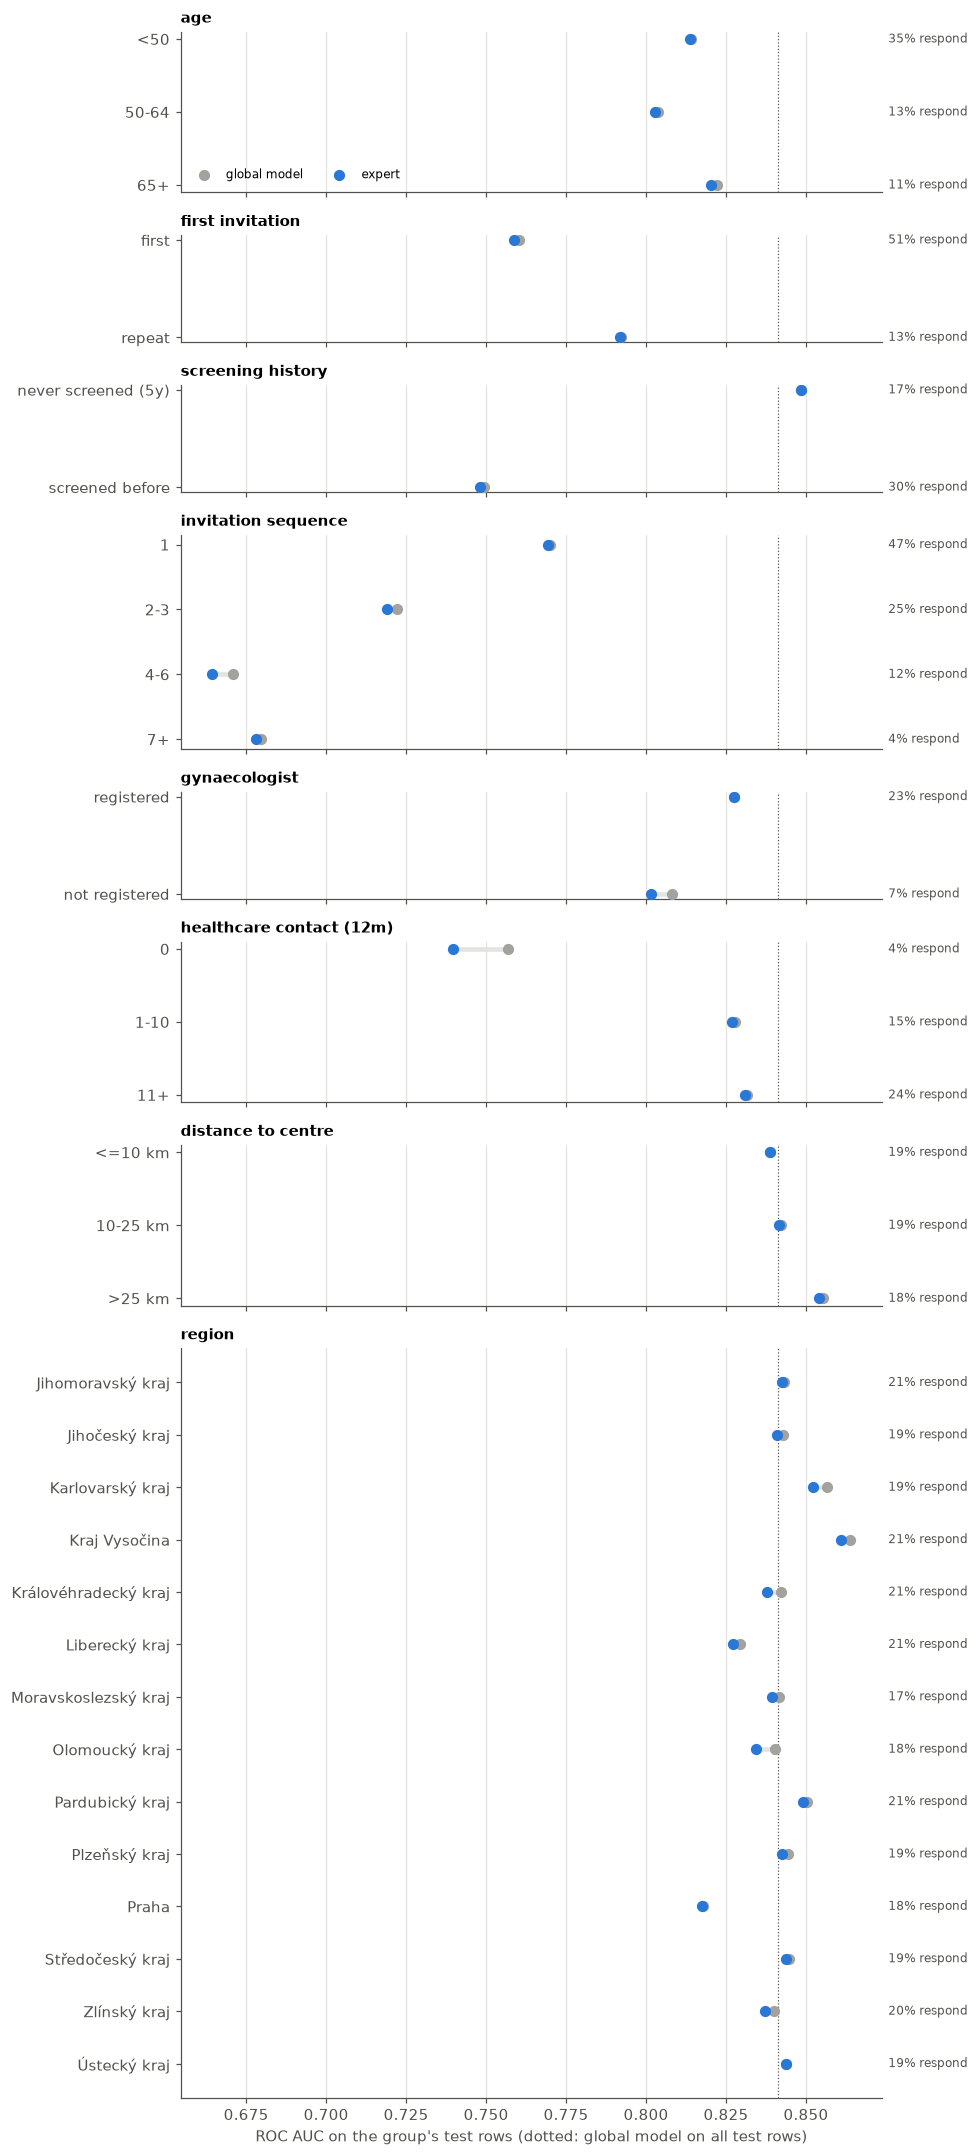

In [3]:
fig, axes = plt.subplots(len(criteria), 1, figsize=(9, 1.0 + 0.55 * len(scores)), sharex=True,
                         gridspec_kw={"height_ratios": [scores.criterion.eq(c).sum() for c in criteria]})
for ax, crit in zip(axes, criteria, strict=True):
    s = scores[scores.criterion == crit].iloc[::-1]
    y = np.arange(len(s))
    ax.hlines(y, s.auc_global, s.auc_expert, color=GRID, lw=3)
    ax.scatter(s.auc_global, y, color=GRAY, s=40, label="global model", zorder=3)
    ax.scatter(s.auc_expert, y, color=BLUE, s=40, label="expert", zorder=3)
    ax.set_yticks(y, s.group)
    ax.set_title(crit)
    ax.axvline(overall.auc_global, color=INK2, lw=0.8, ls=":")
    ax.grid(axis="y", visible=False)
    for yi, rate in zip(y, s.base_rate, strict=True):
        ax.annotate(f"{rate:.0%} respond", (1.0, yi), xycoords=("axes fraction", "data"), xytext=(4, 0),
                    textcoords="offset points", va="center", fontsize=8, color=INK2)
axes[0].legend(loc="lower left", ncol=2, fontsize=8)
axes[-1].set_xlabel("ROC AUC on the group's test rows (dotted: global model on all test rows)")
plt.tight_layout(); plt.show()

## 3. Expert gain with 95% bootstrap interval

Intervals that cross zero mean the expert is not reliably better (or worse) than the global model for that group.

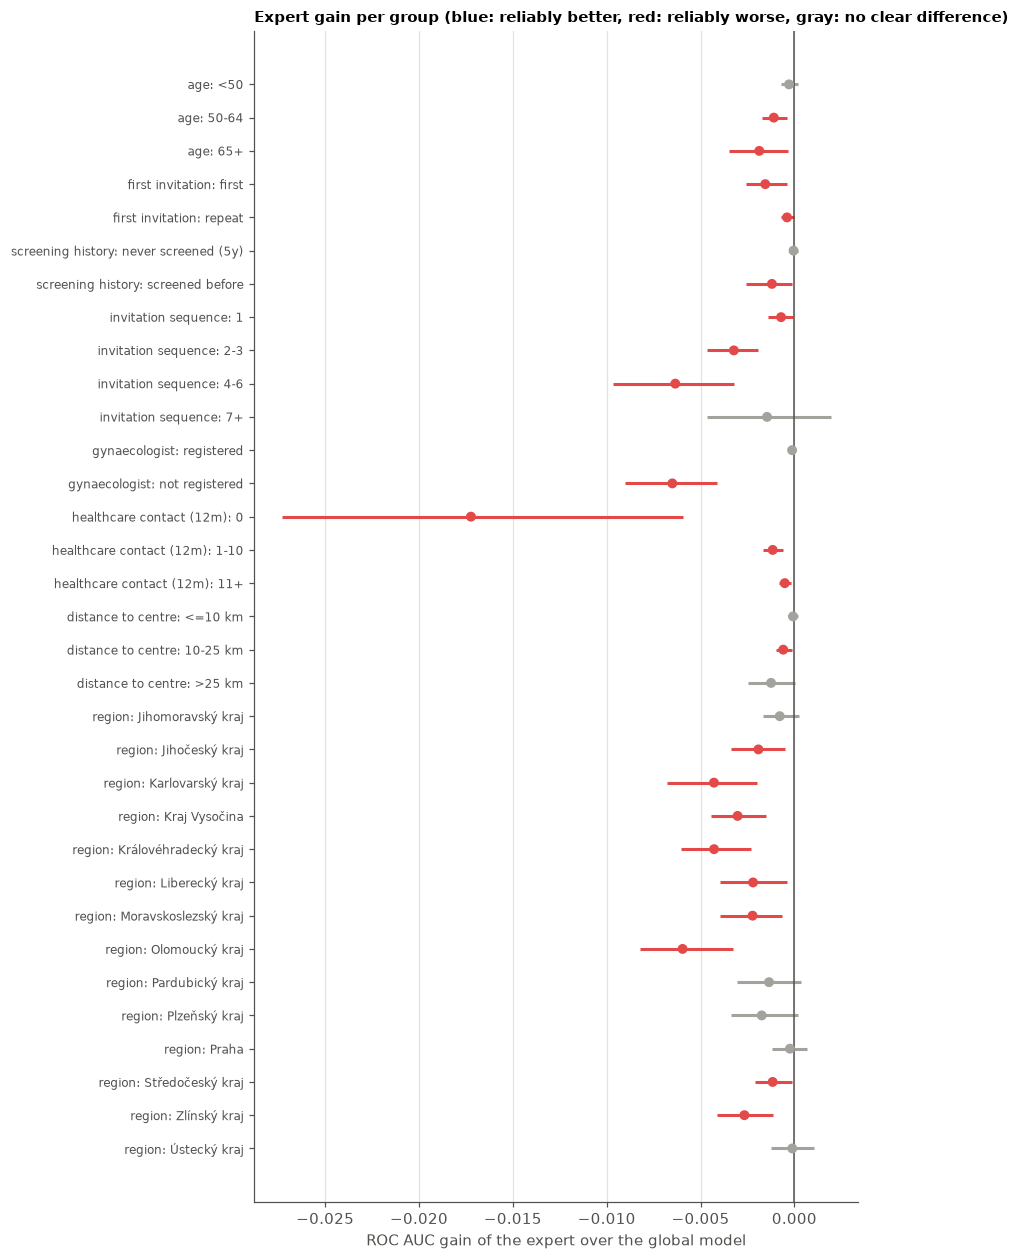

In [4]:
s = scores.query("criterion != 'all'").iloc[::-1].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(8, 0.32 * len(s) + 1))
y = np.arange(len(s))
colors = np.where(s.gain_low > 0, BLUE, np.where(s.gain_high < 0, "#e34948", GRAY))
ax.hlines(y, s.gain_low, s.gain_high, color=colors, lw=2)
ax.scatter(s.gain, y, color=colors, s=30, zorder=3)
ax.axvline(0, color=INK2, lw=1)
ax.set_yticks(y, s.criterion + ": " + s.group, fontsize=8)
ax.grid(axis="y", visible=False)
ax.set_xlabel("ROC AUC gain of the expert over the global model")
ax.set_title("Expert gain per group (blue: reliably better, red: reliably worse, gray: no clear difference)")
plt.tight_layout(); plt.show()

## 4. What drives response inside each group?

Permutation importance of each expert, as a **share of that expert's total importance** (each row sums to 100%).
The first row is the global model on all test rows, for reference. Features are ordered by global importance;
features that are constant inside a group (e.g. `FIRST_INVITATION` among first invitations) have 0.

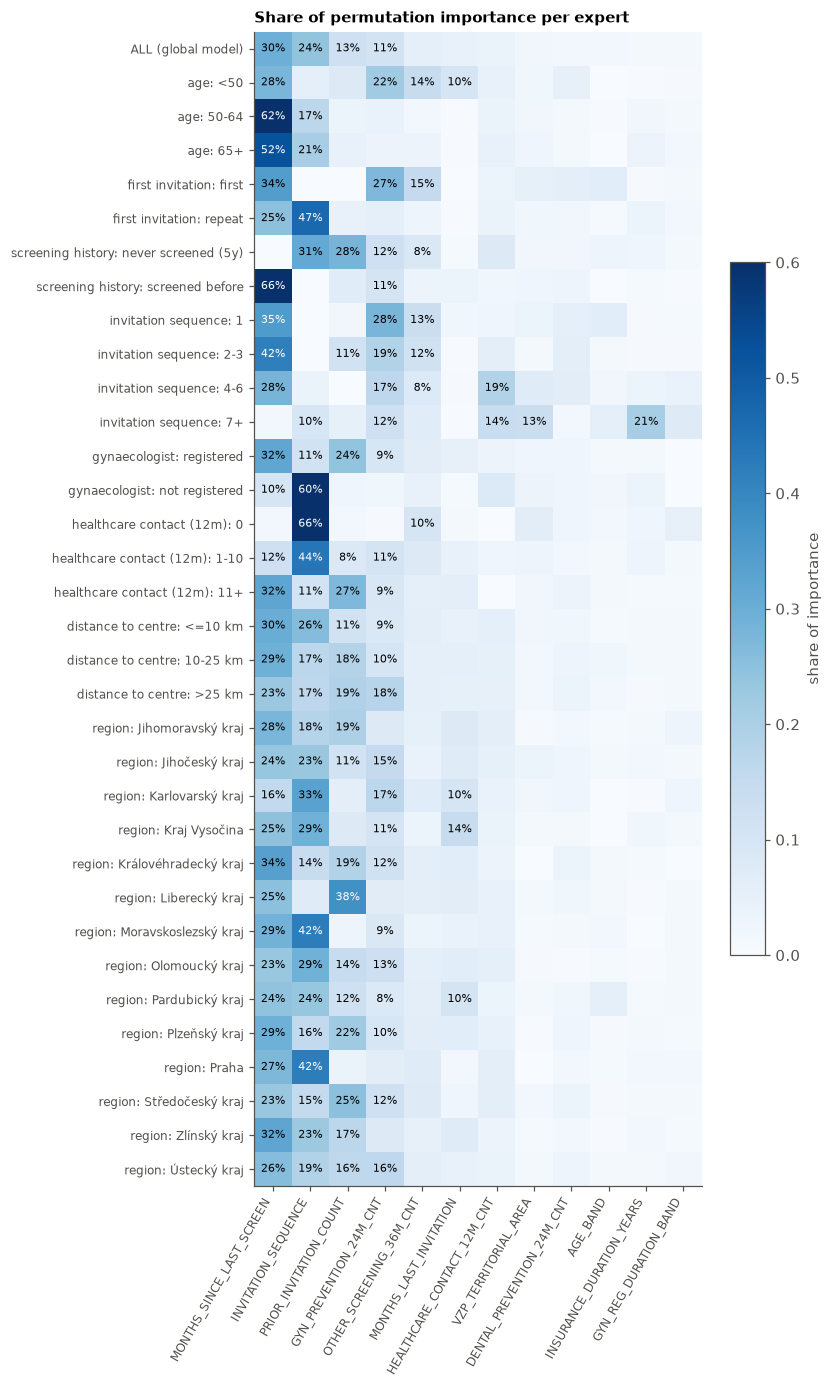

In [5]:
share = imp.clip(lower=0)
share = share.div(share.sum(axis=1), axis=0)
cols = share.loc[("all", "all")].sort_values(ascending=False).index
cols = [c for c in cols if share[c].max() >= 0.03]  # hide features that never matter
share = share[cols]

fig, ax = plt.subplots(figsize=(1.0 + 0.55 * len(cols), 0.33 * len(share) + 1.5))
im = ax.imshow(share.to_numpy(), cmap="Blues", vmin=0, vmax=0.6, aspect="auto")
ax.set_xticks(range(len(cols)), cols, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(share)), [f"{c}: {g}" if c != "all" else "ALL (global model)" for c, g in share.index],
              fontsize=8)
ax.grid(False)
for i in range(share.shape[0]):
    for j in range(share.shape[1]):
        v = share.iat[i, j]
        if v >= 0.08:
            ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=7, color="white" if v > 0.35 else "black")
fig.colorbar(im, ax=ax, shrink=0.6, label="share of importance")
ax.set_title("Share of permutation importance per expert")
plt.tight_layout(); plt.show()

In [6]:
pd.set_option("display.max_colwidth", None)
top = (share.stack().rename("share").reset_index().rename(columns={"level_2": "feature"})
       .sort_values("share", ascending=False).groupby(["criterion", "group"], sort=False).head(3))
top.groupby(["criterion", "group"], sort=False).apply(
    lambda t: ", ".join(f"{f} ({s:.0%})" for f, s in zip(t.feature, t.share, strict=True)), include_groups=False
).reindex(share.index).to_frame("top 3 features")

top 3 features
criterion                group                                                                                                               
all                      all                          MONTHS_SINCE_LAST_SCREEN (30%), INVITATION_SEQUENCE (24%), PRIOR_INVITATION_COUNT (13%)
age                      <50                      MONTHS_SINCE_LAST_SCREEN (28%), GYN_PREVENTION_24M_CNT (22%), OTHER_SCREENING_36M_CNT (14%)
                         50-64                         MONTHS_SINCE_LAST_SCREEN (62%), INVITATION_SEQUENCE (17%), GYN_PREVENTION_24M_CNT (4%)
                         65+                       MONTHS_SINCE_LAST_SCREEN (52%), INVITATION_SEQUENCE (21%), HEALTHCARE_CONTACT_12M_CNT (4%)
first invitation         first                    MONTHS_SINCE_LAST_SCREEN (34%), GYN_PREVENTION_24M_CNT (27%), OTHER_SCREENING_36M_CNT (15%)
                         repeat                        INVITATION_SEQUENCE (47%), MONTHS_SINCE_LAST_SCREEN (25%), GYN_PREVENTION_24M_CNT (6%)
screening history        never screened (5y)            INVITATION_SEQUENCE (31%), PRIOR_INVITATION_COUNT (28%), GYN_PREVENTION_24M_CNT (12%)
                         screened before            MONTHS_SINCE_LAST_SCREEN (66%), GYN_PREVENTION_24M_CNT (11%), PRIOR_INVITATION_COUNT (7%)
invitation sequence      1                        MONTHS_SINCE_LAST_SCREEN (35%), GYN_PREVENTION_24M_CNT (28%), OTHER_SCREENING_36M_CNT (13%)
                         2-3                      MONTHS_SINCE_LAST_SCREEN (42%), GYN_PREVENTION_24M_CNT (19%), OTHER_SCREENING_36M_CNT (12%)
                         4-6                   MONTHS_SINCE_LAST_SCREEN (28%), HEALTHCARE_CONTACT_12M_CNT (19%), GYN_PREVENTION_24M_CNT (17%)
                         7+                      INSURANCE_DURATION_YEARS (21%), HEALTHCARE_CONTACT_12M_CNT (14%), VZP_TERRITORIAL_AREA (13%)
gynaecologist            registered                   MONTHS_SINCE_LAST_SCREEN (32%), PRIOR_INVITATION_COUNT (24%), INVITATION_SEQUENCE (11%)
                         not registered            INVITATION_SEQUENCE (60%), MONTHS_SINCE_LAST_SCREEN (10%), HEALTHCARE_CONTACT_12M_CNT (8%)
healthcare contact (12m) 0                                INVITATION_SEQUENCE (66%), OTHER_SCREENING_36M_CNT (10%), VZP_TERRITORIAL_AREA (6%)
                         1-10                         INVITATION_SEQUENCE (44%), MONTHS_SINCE_LAST_SCREEN (12%), GYN_PREVENTION_24M_CNT (11%)
                         11+                          MONTHS_SINCE_LAST_SCREEN (32%), PRIOR_INVITATION_COUNT (27%), INVITATION_SEQUENCE (11%)
distance to centre       <=10 km                      MONTHS_SINCE_LAST_SCREEN (30%), INVITATION_SEQUENCE (26%), PRIOR_INVITATION_COUNT (11%)
                         10-25 km                     MONTHS_SINCE_LAST_SCREEN (29%), PRIOR_INVITATION_COUNT (18%), INVITATION_SEQUENCE (17%)
                         >25 km                    MONTHS_SINCE_LAST_SCREEN (23%), PRIOR_INVITATION_COUNT (19%), GYN_PREVENTION_24M_CNT (18%)
region                   Jihomoravský kraj            MONTHS_SINCE_LAST_SCREEN (28%), PRIOR_INVITATION_COUNT (19%), INVITATION_SEQUENCE (18%)
                         Jihočeský kraj               MONTHS_SINCE_LAST_SCREEN (24%), INVITATION_SEQUENCE (23%), GYN_PREVENTION_24M_CNT (15%)
                         Karlovarský kraj             INVITATION_SEQUENCE (33%), GYN_PREVENTION_24M_CNT (17%), MONTHS_SINCE_LAST_SCREEN (16%)
                         Kraj Vysočina                INVITATION_SEQUENCE (29%), MONTHS_SINCE_LAST_SCREEN (25%), MONTHS_LAST_INVITATION (14%)
                         Královéhradecký kraj         MONTHS_SINCE_LAST_SCREEN (34%), PRIOR_INVITATION_COUNT (19%), INVITATION_SEQUENCE (14%)
                         Liberecký kraj                PRIOR_INVITATION_COUNT (38%), MONTHS_SINCE_LAST_SCREEN (25%), INVITATION_SEQUENCE (7%)
                         Moravskoslezský kraj          INVITATION_SEQUENCE (42%), MONTHS_SINCE_LAST_SCREEN (29%), GYN_PREVENTION_24M_CNT (9%)
         

## 5. Location: response rate per VZP area

The region experts above group the 75 VZP areas into 14 regions (kraje). This map shows the finer picture: each dot is one area at its geocoded centre, coloured by the share of invitations followed by screening within 12 months (all splits), sized by the number of invitations.

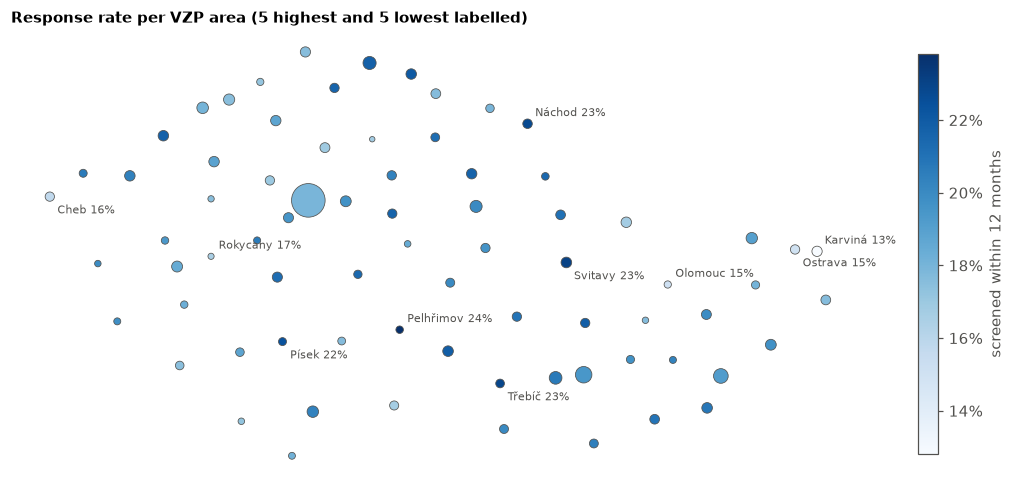

Area response rates range from 12.8% to 23.8% (overall 19.3%).


In [7]:
areas = pd.read_csv("../../data/area_coordinates.csv")
rows = pd.concat(pd.read_csv(f"../../data/splits/{n}.csv", usecols=["VZP_TERRITORIAL_AREA", "SCREENING_12M_FLAG"])
                 for n in ["train", "val", "test"])
rate = rows.groupby("VZP_TERRITORIAL_AREA").SCREENING_12M_FLAG.agg(["mean", "size"])
areas = areas.join(rate, on="area")

fig, ax = plt.subplots(figsize=(10, 5.5))
sc = ax.scatter(areas.lon, areas.lat, c=areas["mean"], s=areas["size"] / 400, cmap="Blues",
                edgecolor=INK2, linewidth=0.5, vmin=areas["mean"].min(), vmax=areas["mean"].max())
labelled = pd.concat([areas.nlargest(5, "mean"), areas.nsmallest(5, "mean")]).sort_values("lon")
for i, (_, r) in enumerate(labelled.iterrows()):  # alternate above / below so neighbours don't collide
    ax.annotate(f"{r.area.title()} {r['mean']:.0%}", (r.lon, r.lat), xytext=(5, 5 if i % 2 else -11),
                textcoords="offset points", fontsize=7, color=INK2)
ax.set_aspect(1 / np.cos(np.radians(49.8)))  # keep Czech geography undistorted
ax.grid(False); ax.set_xticks([]); ax.set_yticks([])
for side in ["left", "bottom"]:
    ax.spines[side].set_visible(False)
fig.colorbar(sc, ax=ax, shrink=0.7, format=lambda v, _: f"{v:.0%}", label="screened within 12 months")
ax.set_title("Response rate per VZP area (5 highest and 5 lowest labelled)")
plt.tight_layout(); plt.show()
print(f"Area response rates range from {areas['mean'].min():.1%} to {areas['mean'].max():.1%} "
      f"(overall {rows.SCREENING_12M_FLAG.mean():.1%}).")

## 6. Conclusions

**1. Experts do not beat one global model.** In all 33 groups (including the 14 regions), the expert is equal to or worse than the global model
(gain between −0.017 and +0.000; no 95% interval lies above zero). Gradient-boosted trees already model interactions, so
the global model learns group-specific patterns *and* benefits from all the data. Experts lose most where their group is
small or rare: no healthcare contact (−0.017, 64k train rows, 4% respond), no gynaecologist (−0.007), invitations 4–6
(−0.006). **Keep one global model**; group splits are a tool for understanding, not for accuracy.

**2. Some groups are much harder to predict.** Within-group ROC AUC (global model):
- hardest: repeat non-responders (invitation 4–6: 0.67, 7+: 0.68), women screened before (0.75), first invitations (0.76),
  no healthcare contact (0.76);
- easiest: never screened in 5 years (0.85), far from a centre (>25 km: 0.85).

The 7+ group is both large (36% of train rows) and nearly unpredictable at a 4% response rate. Better targeting there
needs new information (e.g. channel, GP context), not a better model.

**3. What drives response differs by group** (permutation importance, section 4):
- **Young women / first invitations / sequence 1:** preventive behaviour matters most after timing:
  gynaecologist prevention visits (22–28% of importance) and other screening programmes (13–15%). Women already engaged
  with prevention respond to their first invitation.
- **50+ and women screened before:** timing dominates. `MONTHS_SINCE_LAST_SCREEN` carries 52–66% of importance. These
  women screen regularly; the question is *when* they are due, not *whether* they will come.
- **Never screened in 5 years, no gynaecologist, no healthcare contact:** the invitation history dominates
  (`INVITATION_SEQUENCE` / `PRIOR_INVITATION_COUNT`: 59–66%). The best predictor of ignoring this letter is having ignored
  the previous ones.
- **Chronic non-responders (7+):** no strong signal. The top features are insurance duration, healthcare contact and
  region, each only 13–21%.

**4. Distance to a screening centre barely matters.** Response is 19.4% / 19.3% / 18.5% for ≤10 / 10–25 / >25 km, and
the drivers are the same in all three groups. Caveat: distance is straight-line and per VZP area, not per woman.

**5. Location: regions differ in response rate, not in what drives it.**
- Region experts never help either (gain −0.006 to −0.000). The top drivers in every region are the same:
  invitation history and time since the last screen. The regions differ only in how importance is split between the
  two correlated invitation counters, which is not a real regional difference.
- Response rates do differ (test split): the Moravian-Silesian region is lowest (Moravskoslezský 16.7%, Olomoucký 17.5%), Vysočina
  highest (21.1%). Per area (all splits) the spread is wider: Karviná 12.8%, Ostrava 15.0%, Olomouc 15.1% vs. Pelhřimov 23.8%,
  Svitavy 23.1%, Třebíč 22.9% (map in section 5).
- Prague is the hardest region to predict (ROC AUC 0.818 vs. 0.83–0.86 elsewhere) and responds below average (18.1%).
- So location acts as a **baseline shift** (some areas respond less overall), which the global model already gets from
  `VZP_TERRITORIAL_AREA`. It is useful for planning (e.g. extra effort in the Ostrava/Karviná area), not for a
  separate model.

**Caveats.** Results are for the 12M label, untuned models and the 19 original features. Correlated features
(`INVITATION_SEQUENCE` vs `PRIOR_INVITATION_COUNT`) split their importance between them, so read importance per group
of related features rather than per single feature.